## Introducción

Este cuaderno realiza un **barrido paramétrico** sobre la razón $D_1/D_2$ en el modelo de dos regiones en coordenada desplazada $z'$, donde $D_1$ es la difusividad en la zona superficial $[0, z_c]$ y $D_2 = 2\times10^3\,\text{nm}^2/\mu\text{s}$ es la difusividad bulk fija. Se barren cuatro valores: $D_1/D_2 \in \{0.001,\, 0.01,\, 0.1,\, 1.0\}$.

Para cada valor de $D_1/D_2$ se recalcula la difusividad efectiva armónica $D_\text{eff}$, se recomputan los autovalores axiales $\Lambda_{nm}^2$ en paralelo (joblib, 4 núcleos) y se evalúa $G(t)$ por suma espectral. Parámetros fijos: $d = 15\,\text{nm}$, $R = L = 50d = 750\,\text{nm}$, $z_c = 0.75 R/d$, $\kappa = 0$.

El caso $D_1/D_2 = 1$ corresponde al sistema homogéneo (sin efecto de superficie), mientras que $D_1/D_2 \ll 1$ representa una capa superficial con movilidad muy restringida.

In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G_tworegion_z'_D"):
    os.makedirs("data/temp_G_tworegion_z'_D")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
d = 15               # nm Profundidad de NV
D2 = 2e3             # nm²/us (región volumétrica)
L = R = 50*d        # nm (altura total), nm (radio del cilindro)
varkappa = 0.0       # nm/us
z_c = 0.75/d*L          # nm
n_modes_radial = 100  # Número de modos radiales
m_max = 100           # Número de modos axiales por modo radial
N_z = N_r = 15000    # Número de nodos en z y rho

In [4]:
# -----------------------------------------------------------------------------
# 2. Cálculo de D_eff (promedio armónico), que también se usa en tau = t * D_eff / d^2
# -----------------------------------------------------------------------------
def D_eff_tworegion(D1, D2, z_c, L):
    L1, L2 = z_c, L - z_c
    return (L1 + L2) / (L1/D1 + L2/D2)

In [5]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, varkappa, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, varkappa, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def transcendental_eq(Lambda, alpha_n, kappa, z_c, D1, D2):
    beta_1_sq = np.abs(Lambda**2 - alpha_n**2 * D1) / D1
    beta_2_sq = np.abs(Lambda**2 - alpha_n**2 * D2) / D2
    
    # if beta_1_sq < 0 or beta_2_sq < 0:
    #     return np.inf  # Evitar raíces complejas
    
    beta_1 = np.sqrt(beta_1_sq)
    beta_2 = np.sqrt(beta_2_sq)

    gamma=D2*beta_2*np.sin(beta_2*(L-z_c))-kappa*np.cos(beta_2*(L-z_c))
    theta=D2*beta_2*np.cos(beta_2*(L-z_c))+kappa*np.sin(beta_2*(L-z_c))
    
    # return (D1 * beta_1*np.cos(beta_2*(L-z_c))-kappa*D2*beta_2/D1/beta_1*np.sin(beta_2*(L-z_c))) * np.sin(beta_1 * z_c) + (kappa**beta_1*np.cos(beta_2*(L-z_c))+D2 * beta_2*np.sin(beta_2 * (L - z_c))) * np.cos(beta_1 * z_c)
    return (kappa*D1*beta_1*theta-D2*beta_2*D1*beta_1*gamma)*np.cos(beta_1*z_c)-(D1**2*beta_1**2*theta+kappa*beta_2*D2*gamma)*np.sin(beta_1*z_c)

def find_lambda_roots(alpha, kappa, z_c, D1, D2, m_roots=m_max, step=1e-2):
    Lambda_min = alpha * np.sqrt(D2)
    roots = []
    
    Lambda_current = Lambda_min
    while len(roots) < m_max:
        # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
        try:
            root = brentq(transcendental_eq, Lambda_current, Lambda_current + step,
                           args=(alpha,kappa,z_c, D1, D2), xtol=1e-6)
            roots.append(root**2)
            Lambda_current = root + step  # Mover el inicio para la próxima búsqueda
        except ValueError:
            Lambda_current += step
    
    return np.array(roots[:m_max])  # Devuelve hasta m_max raíces

# Definir fz_raw vectorizado
def fz_raw(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m):
    z = np.array(z_val, dtype=float)
    # modos
    r_mode = alpha_n[n]
    z_mode = eigenvalues_ax[n][m]
    
    beta_1 = np.sqrt(np.abs(z_mode - r_mode**2 * D1) / D1)
    beta_2 = np.sqrt(np.abs(z_mode - r_mode**2 * D2) / D2)
    
    # expresiones para cada región
    expr1 = np.cos(beta_1 * (z)) + (kappa / (D1 * beta_1+1e-30)) * np.sin(beta_1 * (z))
    expr2 = (np.cos(beta_1 * z_c) + (kappa / (D1 * beta_1+1e-30)) * np.sin(beta_1 * z_c)) * \
            ((np.sin(beta_2*(L-z_c))-kappa*np.cos(beta_2*(L-z_c)))/(np.cos(beta_2*(L-z_c))+kappa*np.sin(beta_2*(L-z_c)))*\
            np.sin(beta_2 * (z - z_c)) + np.cos(beta_2 * (z - z_c)))
    
    # seleccionar por región
    return np.where(z <= z_c, expr1, expr2)
    
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [6]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
D_fraction_list = [0.001, 0.01, 0.1, 1]

In [7]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de J0(alpha_n * rho) y demás datos independientes
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# N_quad = 1000
# rho_nodes = np.linspace(0.0, R, N_quad)  # np.linspace(0,R,N_quad)
# z_nodes = np.linspace(0.0, L, N_quad)   # en [d, L+d]
# rho0 = 0.0
# z0 = 0.0
# dr = rho_nodes[1] - rho_nodes[0]
# dz = z_nodes[1] - z_nodes[0]

# # 5.2 Construcción de la red J0(alpha_n * rho) se hará DENTRO del bucle,
# #     porque alpha_n depende de varkappa.

# # 5.3 Construcción de Z_tens (modos axiales ante nodos z_nodes) se hará DENTRO del bucle,
# #     ya que los autovectores axiales dependen de varkappa.

# # 5.4 Matriz f_mat (factor dipolar) es independiente de varkappa:
# R2 = rho_nodes**2
# Z2 = (z_nodes+d + 1e-30)**2   # pequeño desplazamiento para evitar división por cero
# f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # forma (N_quad, N_quad)
# f0_mat = (3*(z0+d)**2-rho0**2)/(rho0**2+(z0+d)**2)**2.5
# rho_factor = (rho_nodes[:, None] * f0_mat * f_mat * dr * dz)

# # 5.5 Vector de tiempos t en los que se evaluará G(t)
# t_values = np.logspace(-3, 4, N_quad)   # forma (N_quad,)

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de f(ρ,z') y medida ρ dρ dz' (independientes de D1)
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z' para G(t):
N_quad = 1000
rho_nodes = np.linspace(0.0, R, N_quad)   # [0, R]
z_nodes  = np.linspace(0.0, L, N_quad)    # [0, L] = z' en el modelo de dos regiones

dr = rho_nodes[1] - rho_nodes[0]
dz = z_nodes[1]  - z_nodes[0]

# 5.2 Factor dipolar f(ρ,z') en la malla (Nr, Nz)
#     Distancia al NV: z' + d
R2 = rho_nodes**2
Z2 = (z_nodes + 1e-30)**2   # z_nodes empieza en d; no se suma d de nuevo
f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # shape (Nr, Nz)

# 5.3 Medida cilíndrica ρ dρ dz'
measure = rho_nodes[:, None] * dr * dz    # shape (Nr, 1)

# 5.4 Matriz F(ρ,z') = ρ dρ dz' f(ρ,z')
F = measure * f_mat                       # shape (Nr, Nz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values = np.logspace(-3, 4, N_quad)     # (N_quad,)

In [9]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada D1/D2, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
D_eff_list = []

for f in D_fraction_list:
    print(f"--- Calculando G(t) para D1/D2 = {f} ---")
    D1 = f * D2

    # 6.1. Difusividad efectiva del modelo de dos regiones
    D_eff = D_eff_tworegion(D1, D2, z_c, L)
    D_eff_list.append(D_eff)

    # 6.2. Hallar raíces alpha_n (n_modes_radial valores) para la parte radial
    alpha_n = find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.3. Modos radiales normalizados en nodos rho
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # shape (n_modes_radial, N_quad)

    # 6.4. Autovalores axiales λ_{n,m}(D1)
    eigenvalues_ax = Parallel(n_jobs=4, verbose=1)(
        delayed(find_lambda_roots)(alpha, varkappa, z_c, D1, D2,
                                   m_roots=m_max, step=1e-2)
        for n, alpha in enumerate(alpha_n)
    )
    eigenvalues_ax = np.array(eigenvalues_ax)   # shape (n_modes_radial, m_max)

    # 6.5. Normalizar modos axiales en z' para cada (n,m)
    C_norm = np.zeros((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_vals = fz_raw(z_nodes, z_c, D1, D2, varkappa, alpha_n, eigenvalues_ax, n, m)
            integral = np.trapz(Z_vals**2, z_nodes)
            C_norm[n, m] = 1.0 / np.sqrt(integral + 1e-30)

    def fz(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m):
        return C_norm[n, m] * fz_raw(z_val, z_c, D1, D2, kappa, alpha_n, eigenvalues_ax, n, m)

    # 6.6. Construir Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_tens[:, n, m] = fz(z_nodes, z_c, D1, D2, varkappa, alpha_n, eigenvalues_ax, n, m)

    # -------------------------------------------------------------------------
    # 6.7. Coeficientes de proyección de f sobre los modos: Cproj_{n,m}(D1)
    #      Cproj_nm = ∫ ρ dρ dz' f(ρ,z') R_n(ρ) Z_{n,m}(z';D1)
    #      → Discretizado con F(ρ,z') = ρ dρ dz' f(ρ,z')
    # -------------------------------------------------------------------------
    Cproj_nm = np.zeros((n_modes_radial, m_max))

    for n in range(n_modes_radial):
        # g_n(z_k) = ∑_i R_n(ρ_i) F(ρ_i, z_k)
        g_n = np.dot(R0_mat[n, :], F)   # shape (N_quad,)
        for m in range(m_max):
            # Cproj_nm[n,m] = ∑_k g_n(z_k) Z_{n,m}(z_k)
            Cproj_nm[n, m] = np.dot(g_n, Z_tens[:, n, m])

    # -------------------------------------------------------------------------
    # 6.8. Cálculo de G(t; D1) con la suma espectral:
    #      G(t) = (5 / 16π) * ∑_{n,m} Cproj_nm^2 e^{-λ_{nm} t}
    # -------------------------------------------------------------------------
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # shape (n_modes_radial, m_max)
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((Cproj_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.9. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    temp_filename = os.path.join("data/temp_G_tworegion_z'_D", f"G_D1_{int(f*D2)}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_D1{}".format(f*D2)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    del G_values
    del data_to_save

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")


--- Calculando G(t) para D1/D2 = 0.001 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  68 tasks      | elapsed:    1.6s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    1.7s finished
C:\Users\allan\AppData\Local\Temp\ipykernel_6976\1625638541.py:29: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(Z_vals**2, z_nodes)


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_2.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 0.01 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    1.4s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_20.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 0.1 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  76 tasks      | elapsed:    1.6s
[Parallel(n_jobs=4)]: Done  93 out of 100 | elapsed:    2.0s remaining:    0.1s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    2.0s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_200.dat' y liberado G_values.

--- Calculando G(t) para D1/D2 = 1 ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  76 tasks      | elapsed:    2.1s
[Parallel(n_jobs=4)]: Done  93 out of 100 | elapsed:    2.4s remaining:    0.1s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    2.5s finished


  → Guardado temporal en 'data/temp_G_tworegion_z'_D\G_D1_2000.dat' y liberado G_values.



In [11]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'VariateD1_G_vs_t_tworegion_z'.dat' ...")

primero = True
lista_Gcols = []

for f in D_fraction_list:
    temp_filename = os.path.join("data/temp_G_tworegion_z'_D", f"G_D1_{int(f*D2)}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_D1{int(f*D2)}' for f in D_fraction_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/VariateD1_G_vs_t_tworegion_z'.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'VariateD1_G_vs_t_tworegion_z'.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'VariateD1_G_vs_t_tworegion_z'.dat' ...
→ Archivo final 'VariateD1_G_vs_t_tworegion_z'.dat' creado con columnas:
    ['Tiempo(s)', 'G_D12', 'G_D120', 'G_D1200', 'G_D12000']


In [12]:
df = pd.read_csv("data/VariateD1_G_vs_t_tworegion_z'.dat",delim_whitespace=True,comment='#')

C:\Users\allan\AppData\Local\Temp\ipykernel_6976\3852967609.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv("data/VariateD1_G_vs_t_tworegion_z'.dat",delim_whitespace=True,comment='#')


In [13]:
tau_values=t_values*D_eff_list[3]/d**2

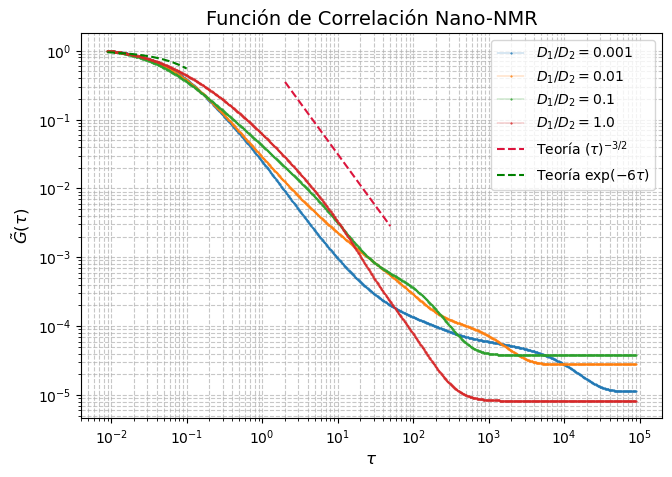

In [14]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, df.G_D12/df.G_D12[0], "o-", label=r"$D_1/D_2=0.001$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D120/df.G_D120[0], "o-", label=r"$D_1/D_2=0.01$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D1200/df.G_D1200[0], "o-", label=r"$D_1/D_2=0.1$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_D12000/df.G_D12000[0], "o-", label=r"$D_1/D_2=1.0$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=50)], tau_values[(tau_values>=2)&(tau_values<=50)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[(tau_values<=0.1)], np.exp(-6*tau_values[(tau_values<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_tworegion_z'_D1Variation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Conclusiones

El barrido sobre la razón $D_1/D_2$ en el modelo de dos regiones muestra claramente cómo la reducción de difusividad en la capa superficial modifica $\tilde{G}(\tau)$:

- Para $D_1/D_2 = 1$ (sin efecto de superficie), $G(t)$ sigue el comportamiento homogéneo universal ($\exp(-6\tau)$ → $\tau^{-3/2}$).
- Al reducir $D_1/D_2$, la función de correlación se vuelve más lenta a tiempos intermedios: las moléculas en la capa de baja difusividad contribuyen a la señal durante más tiempo.
- La escala temporal adimensional $\tau = D_\text{eff}\, t / d^2$ se desplaza al variar $D_\text{eff}$ con la razón $D_1/D_2$, modificando el punto de cruce entre los dos regímenes asintóticos.

Este análisis permite cuantificar la sensibilidad de la señal Nano-NMR a la razón de difusividades entre la capa superficial y el bulk, parámetro clave para interpretar experimentos de espectroscopía en interfaces.